![illustration](notes/Kitaev-GME/figures/minimal-system_brick-wall_diagonal.svg)

In [1]:
import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt
#from scipy import linalg as la
#from numpy import linalg as LA
from SpinModelDM import SpinSystem
#from FittingTool import FittingToolLib as ft
#import os
import json
#import shutil

width = 4
height = 4
DM = SpinSystem(width=width, height=height) # create a module

Creating CorrTable
CorrTable creation complete


In [2]:
from SpinModelDM import SpinSystem
import numpy as np
DM = SpinSystem(width=4, height=4)

label = 24
print(DM.Coefficient_engine(label=label))
print(DM.Coefficient_engine(label=DM.translation_label(label=label,
                                                     move=[0,2])))
print(DM.Coefficient_engine(label=DM.translation_label(label=label,
                                                     move=[1,1])))
print(DM.Coefficient_engine(label=DM.translation_label(label=label,
                                                     move=[0,1])))



Creating CorrTable
CorrTable creation complete
[0, np.float64(-0.1118033988749895)]
[0, np.float64(-0.1118033988749895)]
[0, np.float64(0.11180339887498944)]
[0, np.float64(0.11180339887498944)]


In [4]:
DM.norm_cond_test(update=True)

Creating coefficient table for Jx=1.000, Jy=1.000, Jz=1.000, mag=0.000
the representative that is equivalent to 65535 is 65535
Progress: 1/10
Progress: 2/10
Progress: 3/10
Progress: 4/10
Progress: 5/10
Progress: 6/10
Progress: 7/10
Progress: 8/10
Progress: 9/10
Progress: 10/10


np.float64(0.9999999999999483)

In [14]:
DM.stab_renyi_entropy(alpha=1)

np.float64(2.843689401105742)

# Test basic functions

## Transformations between different methods to label the lattice sites

In [15]:
print(DM.dictionary_n_to_l(label=5))
print(DM.dictionary_n_to_c(label=3))
print(DM.dictionary_l_to_n(layer=-1, site=-1))

(1, 1)
(2, -1, 1)
15


## Computing two-points correlation functions
toric code limit

In [16]:
# dimerized in the z-direction
DM.Jx = 0.01
DM.Jy = 0.01
DM.Jz = 1
print(DM.corr(na=5, nb=2))
print(DM.corr(na=5, nb=6))

# dimerized in the x-direction
DM.Jx = 1
DM.Jy = 0.01
DM.Jz = 0.01
print(DM.corr(na=5, nb=2))
print(DM.corr(na=5, nb=6))

0.9999500149950018
0.004999000299899977
0.00500024991874403
0.999974994375469


Finite-size effect: The correlation functions from different directions are not equal even in the isotropic limit.

In [18]:
DM.Jx, DM.Jy, DM.Jz = 1, 1, 1
update = False
print(DM.corr(na=2*width-1, nb=0, update=update))
print(DM.corr(na=1, nb=0, update=update))
print(DM.corr(na=width-1, nb=0, update=update))

0.6118033988749895
0.47360679774997894
0.47360679774997894


## The direction of a dimer (edge)

In [19]:
DM.dimer_direction(n1=5, n2=6)

'X'

In [20]:
DM.string_op(na=1, nb=2)

<Compressed Sparse Row sparse matrix of dtype 'complex128'
	with 65536 stored elements and shape (65536, 65536)>

## String Coefficients

### For a single value of $\alpha$

Creating CorrTable
CorrTable creation complete
Creating CorrTable
CorrTable creation complete
Creating coefficient table for Jx=0.233, Jy=0.233, Jz=0.533, mag=0.000
Progress: 1/10
Progress: 2/10
Progress: 3/10
Progress: 4/10
Progress: 5/10
Progress: 6/10
Progress: 7/10
Progress: 8/10
Progress: 9/10
Progress: 10/10
Sum rule check: 0.9999999999999483
T_fit = [0.04065271]


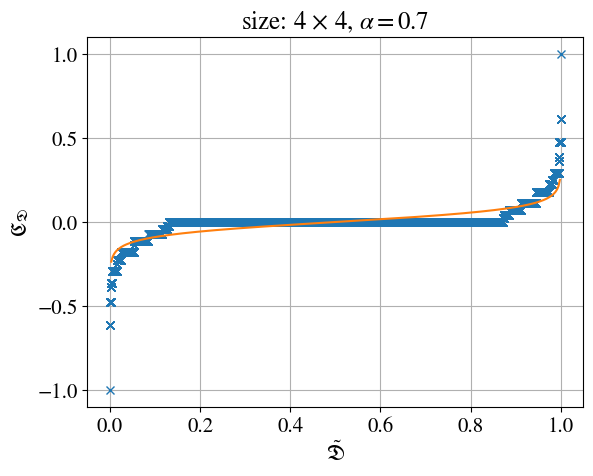

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from SpinModelDM import SpinSystem
import json
import os
from scipy.optimize import curve_fit

import matplotlib
matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams.update({'font.size': 15})

width = 4
height = 4
DM = SpinSystem(width=width, height=height) # create a module

a = 0.7
# DM.Jx = DM.Jy = a
# DM.Jz = 3 - 2*a

DM.Jx = DM.Jy = a/3
DM.Jz = 1 - 2*a/3

# if os.path.isfile(DM.datapath + '/CoeTable.json'):
#     with open(DM.datapath + '/CoeTable.json', 'r') as file:
#         coe_dict = json.load(file)
# else:
#     DM.calculate_CoefficientTable_approx(lazy=False)
#     with open(DM.datapath + '/CoeTable_approx.json', 'r') as file:
#         coe_dict = json.load(file)

coe_info = np.array(list(DM.calculate_CoefficientTable(update=True).values()))
coe_list = coe_info[:,1]
coe_list.sort()

print(f'Sum rule check: {DM.norm_cond_test(approximate=False, lazy=False)}')

# normalized_config = np.hstack((np.arange(DM.num_total_config)[:int(len(coe_list)/2)], 
#                                np.arange(DM.num_total_config)[-int(len(coe_list)/2):])) / DM.num_total_config
normalized_config = np.arange(len(coe_list)) / len(coe_list)
plt.plot(normalized_config, coe_list, 'x')

plt.title(fr'size: {DM.width} $\times$ {DM.height}, $\alpha={{{a}}}$')
plt.xlabel(r'$\tilde{\mathfrak{D}}$')
plt.ylabel(r'$\mathfrak{C}_{\mathfrak{D}}$')
plt.grid()
plt.tight_layout

step = 100
curvfit_x_range = normalized_config[step::step]
func_fit = lambda x, T: -T*np.log(1/x - 1)
T_fit, err = curve_fit(f=func_fit, xdata=curvfit_x_range, ydata=coe_list[step::step])
print(f'T_fit = {T_fit}')
plt.plot(curvfit_x_range, func_fit(x=curvfit_x_range, T=T_fit), '-')

os.makedirs(f'figures/coefficients-distribution/w_{DM.width}_h_{DM.height}', exist_ok=True)
plt.savefig(f'figures/coefficients-distribution/w_{DM.width}_h_{DM.height}/Jx_{DM.Jx:.3f}_Jy_{DM.Jy:.3f}_Jz_{DM.Jz:.3f}.pdf', dpi=300)


import csv
with open(f'figures/coefficients-distribution/w_{DM.width}_h_{DM.height}/Jx_{DM.Jx:.3f}_Jy_{DM.Jy:.3f}_Jz_{DM.Jz:.3f}.csv', 'w') as file:
    writer = csv.writer(file)
    writer.writerow(coe_list)

### Comparism with different values of $\alpha$

Creating coefficient table for Jx=0.000, Jy=0.000, Jz=1.000, mag=0.000
Progress: 1/10
Progress: 2/10
Progress: 3/10
Progress: 4/10
Progress: 5/10
Progress: 6/10
Progress: 7/10
Progress: 8/10
Progress: 9/10
Progress: 10/10
Jx,Jy,Jz = 0.000, 0.000, 1.000
Sum rule chack: 1.0
Creating coefficient table for Jx=0.111, Jy=0.111, Jz=0.778, mag=0.000
Progress: 1/10
Progress: 2/10
Progress: 3/10
Progress: 4/10
Progress: 5/10
Progress: 6/10
Progress: 7/10
Progress: 8/10
Progress: 9/10
Progress: 10/10
Jx,Jy,Jz = 0.111, 0.111, 0.778
Sum rule chack: 0.999999999999984
Creating coefficient table for Jx=0.222, Jy=0.222, Jz=0.556, mag=0.000
Progress: 1/10
Progress: 2/10
Progress: 3/10
Progress: 4/10
Progress: 5/10
Progress: 6/10
Progress: 7/10
Progress: 8/10
Progress: 9/10
Progress: 10/10
Jx,Jy,Jz = 0.222, 0.222, 0.556
Sum rule chack: 1.000000000000017
Creating coefficient table for Jx=0.333, Jy=0.333, Jz=0.333, mag=0.000
Progress: 1/10
Progress: 2/10
Progress: 3/10
Progress: 4/10
Progress: 5/10
Progres

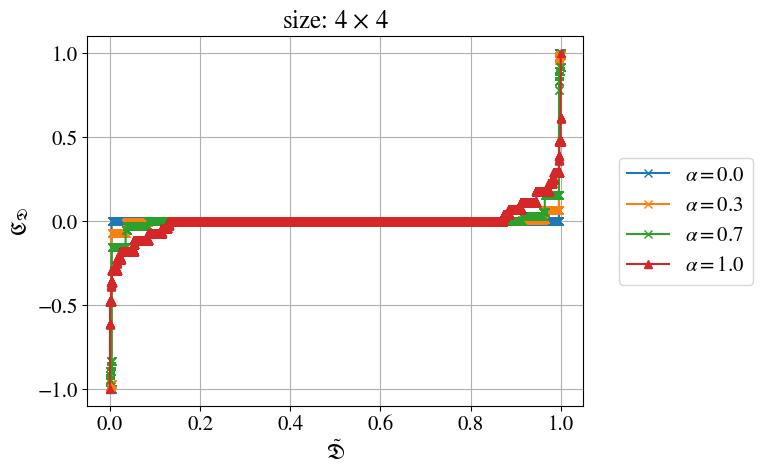

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from SpinModelDM import SpinSystem
import json
import os

import matplotlib
matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams.update({'font.size': 15})

width = 4
height = 4
DM = SpinSystem(width=width, height=height) # create a module

a_range = np.linspace(0, 1, 4, endpoint=True)
for a in a_range:
    DM.Jx = DM.Jy = a/3
    DM.Jz = 1 - 2*a/3

    # if os.path.isfile(DM.datapath + '/CoeTable.json'):
    #     with open(DM.datapath + '/CoeTable.json', 'r') as file:
    #         coe_dict = json.load(file)
    # else:
    #     DM.calculate_CoefficientTable()
    #     with open(DM.datapath + '/CoeTable.json', 'r') as file:
    #         coe_dict = json.load(file)
    coe_info = np.array(list(DM.calculate_CoefficientTable(update=True).values()))
    coe_list = coe_info[:,1]
    coe_list.sort()
    print('Jx,Jy,Jz = %.3f, %.3f, %.3f' % (DM.Jx, DM.Jy, DM.Jz))

    print(f'Sum rule chack: {sum(np.array(coe_list)**2) / 2**(DM.N/2)}')

    if a < 3/4:
        normalized_config = np.arange(len(coe_list)) / len(coe_list)
        plt.plot(normalized_config, coe_list, '-x', label=rf'$\alpha = {{{a:.1f}}}$')
    else:
        normalized_config = np.arange(len(coe_list)) / len(coe_list)
        plt.plot(normalized_config, coe_list, '-^', label=rf'$\alpha = {{{a:.1f}}}$')

plt.title(fr'size: {DM.width} $\times$ {DM.height}')
plt.xlabel(r'$\tilde{\mathfrak{D}}$')
plt.ylabel(r'$\mathfrak{C}_{\mathfrak{D}}$')
plt.legend(bbox_to_anchor=(1.05, 0.5), loc='center left')
plt.grid()
plt.tight_layout

os.makedirs(f'figures/coefficients-distribution', exist_ok=True)
plt.savefig(f'figures/coefficients-distribution/w_{DM.width}_h_{DM.height}_compare.pdf', dpi=300)

### Find the most important configurations

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from SpinModelDM import SpinSystem
import json
import os
from SpinModelDM import number_to_config

import matplotlib
matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams.update({'font.size': 15})

width = 4
height = 4
DM = SpinSystem(width=width, height=height) # create a module

a = 1
DM.Jx = DM.Jy = a
DM.Jz = 3 - 2*a

# DM.Jx = DM.Jy = a/3
# DM.Jz = 1 - 2*a/3

if os.path.isfile(DM.datapath + '/CoeTable.json'):
    with open(DM.datapath + '/CoeTable.json', 'r') as file:
        coe_dict = json.load(file)
else:
    DM.calculate_CoefficientTable()
    with open(DM.datapath + '/CoeTable.json', 'r') as file:
        coe_dict = json.load(file)

coe_list = np.array([coe_dict['%d'%n] for n in np.arange(DM.num_total_config)])
sorted_index = np.argsort(coe_list)
sorted_coe_array = coe_list[sorted_index]

# plt.plot(np.arange(DM.num_total_config), sorted_coe_array)

for label in np.arange(5000):
    # print(f'config: {number_to_config(N=DM.N, number=sorted_index[label])}; coe = {sorted_coe_array[label]}')
    print(f'config: {number_to_config(N=DM.N, number=sorted_index[-label-1])}; coe = {sorted_coe_array[-label-1]}')

config: ([], []); coe = 1.0
config: ([], []); coe = 1.0
config: ([1, 3, 7, 9, 11, 13, 15], [0, 4, 6, 8, 10, 12, 14]); coe = 0.6118033988749895
config: ([1], [14]); coe = 0.6118033988749895
config: ([3], [12]); coe = 0.6118033988749895
config: ([11], [4]); coe = 0.6118033988749895
config: ([15], [8]); coe = 0.6118033988749895
config: ([5], [2]); coe = 0.6118033988749895
config: ([13], [10]); coe = 0.6118033988749895
config: ([9], [6]); coe = 0.6118033988749895
config: ([7], [0]); coe = 0.6118033988749895
config: ([3, 5, 7, 9, 11, 13, 15], [0, 2, 4, 6, 8, 10, 12]); coe = 0.6118033988749894
config: ([1, 3, 5, 9, 11, 13, 15], [2, 4, 6, 8, 10, 12, 14]); coe = 0.6118033988749894
config: ([1, 3, 5, 7, 9, 11, 15], [0, 2, 4, 6, 8, 12, 14]); coe = 0.6118033988749894
config: ([1, 3, 5, 7, 9, 11, 13], [0, 2, 4, 6, 10, 12, 14]); coe = 0.6118033988749894
config: ([1, 5, 7, 9, 11, 13, 15], [0, 2, 4, 6, 8, 10, 14]); coe = 0.6118033988749894
config: ([1, 3, 5, 7, 11, 13, 15], [0, 2, 4, 8, 10, 12, 14]);

In [12]:
DM.Coefficient_engine(setA=[1, 3, 7, 9, 11, 13, 15], setB=[0, 4, 6, 8, 10, 12, 14])

np.float64(0.6118033988749895)

![illustration](notes/Kitaev-GME/figures/minimal-system_brick-wall_diagonal.svg)

# Computing the ground state density matrix

Notice that the format of the output and the saved density matrix is ``scipy.sparse``. To load the density matrix, please use ``sp.load_npz`` instead of ``np.load``.

In [22]:
# rho = DM.density_matrix(update=True)

# Magic Transition

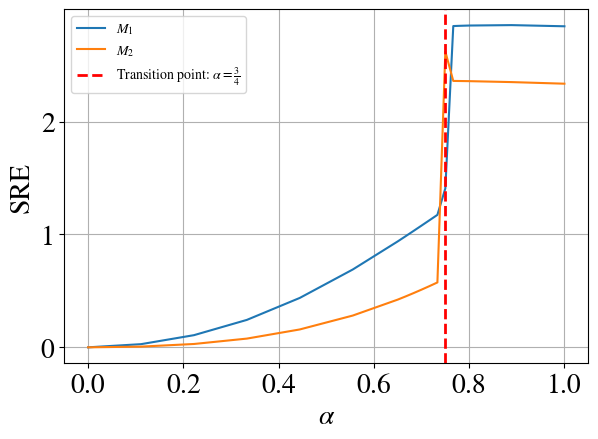

In [6]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from SpinModelDM import SpinSystem
import os

matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams.update({'font.size': 20})

width = 4
height = 4
DM = SpinSystem(width=width, height=height) # create a module

a_range = np.linspace(0, 1, 10, endpoint=True)
a_range = np.concatenate((a_range, np.linspace(0.65, 0.8, 10, endpoint=True)))
a_range.sort()

### exact
for n in [1,2]:
    entropy_data = np.zeros_like(a_range)
    index = 0
    for a in a_range:
        DM.Jx = DM.Jy = a/3
        DM.Jz = 1 - 2*a/3

        entropy_data[index] += DM.stab_renyi_entropy(alpha=n, update=False) 
        index += 1

    plt.plot(a_range, entropy_data, label= r'$M_{{{}}}$'.format(n))


plt.axvline(x=3/4,          # dashed line, indicating the theoretical value
            color='red', 
            linestyle='--', 
            linewidth=2, 
            label=r"Transition point: $\alpha = \frac{3}{4}$")
plt.xlabel(r'$\alpha$')
plt.ylabel('SRE')
plt.legend(fontsize='10')
# plt.text(0, 1, r'Lattice size: $%d \times %d$' % (DM.width, DM.height) , fontsize=20)  # + '%d'%DM.width + r'$\times$' + '%d'%DM.height
plt.tight_layout()
plt.grid()

os.makedirs('figures/stab-renyi-entropy', exist_ok=True)
plt.savefig('figures/stab-renyi-entropy/w_%d_h_%d.pdf' % (DM.width, DM.height), dpi=300)

## Magic Transition with Magnetic Field

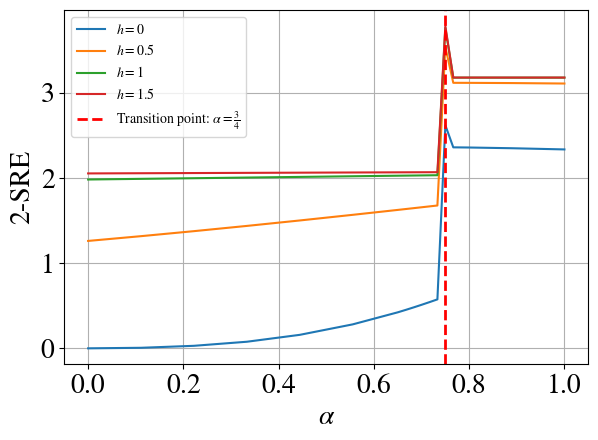

In [5]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from SpinModelDM import SpinSystem
import os

matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams.update({'font.size': 20})

width = 4
height = 4
DM = SpinSystem(width=width, height=height) # create a module

a_range = np.linspace(0, 1, 10, endpoint=True)
a_range = np.concatenate((a_range, np.linspace(0.65, 0.8, 10, endpoint=True)))
a_range.sort()

### exact
for h in [0,0.5,1,1.5]:
    DM.h = h
    entropy_data = np.zeros_like(a_range)
    index = 0
    for a in a_range:
        DM.Jx = DM.Jy = a/3
        DM.Jz = 1 - 2*a/3

        entropy_data[index] += DM.stab_renyi_entropy(alpha=2, update=False) 
        index += 1

    plt.plot(a_range, entropy_data, label= rf'$h = {h}$')


plt.axvline(x=3/4,          # dashed line, indicating the theoretical value
            color='red', 
            linestyle='--', 
            linewidth=2, 
            label=r"Transition point: $\alpha = \frac{3}{4}$")
plt.xlabel(r'$\alpha$')
plt.ylabel('2-SRE')
plt.legend(fontsize='10')
# plt.text(0, 1, r'Lattice size: $%d \times %d$' % (DM.width, DM.height) , fontsize=20)  # + '%d'%DM.width + r'$\times$' + '%d'%DM.height
plt.tight_layout()
plt.grid()

os.makedirs('figures/stab-renyi-entropy', exist_ok=True)
plt.savefig('figures/stab-renyi-entropy/w_%d_h_%d_varying-mag-field.pdf' % (DM.width, DM.height), dpi=300)

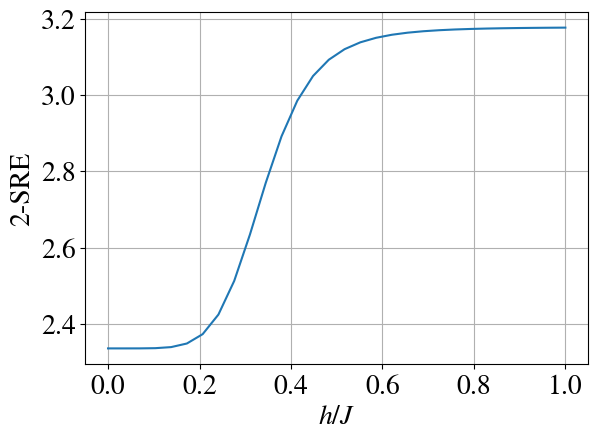

In [8]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from SpinModelDM import SpinSystem
import os

matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams.update({'font.size': 20})

width = 4
height = 4
DM = SpinSystem(width=width, height=height) # create a module

h_range = np.linspace(0, 1, 30, endpoint=True)
# a_range = np.concatenate((a_range, np.linspace(0.65, 0.8, 10, endpoint=True)))
# a_range.sort()

### exact
a = 1
DM.Jx = DM.Jy = a/3
DM.Jz = 1 - 2*a/3

index = 0
entropy_data = np.zeros_like(h_range)
for h in h_range:
    DM.h = h

    entropy_data[index] = DM.stab_renyi_entropy(alpha=2, update=False) 
    index += 1

plt.plot(h_range, entropy_data)


# plt.axvline(x=3/4,          # dashed line, indicating the theoretical value
#             color='red', 
#             linestyle='--', 
#             linewidth=2, 
#             label=r"Transition point: $\alpha = \frac{3}{4}$")
plt.xlabel(r'$h/J$')
plt.ylabel('2-SRE')
plt.grid()
# plt.legend(fontsize='10')
# plt.text(0, 1, r'Lattice size: $%d \times %d$' % (DM.width, DM.height) , fontsize=20)  # + '%d'%DM.width + r'$\times$' + '%d'%DM.height
plt.tight_layout()

os.makedirs('figures/stab-renyi-entropy', exist_ok=True)
plt.savefig('figures/stab-renyi-entropy/w_%d_h_%d_vs-mag.pdf' % (DM.width, DM.height), dpi=300)